# Treino ampliado com novas observações SPHEREx

Este conjunto usa novas exposições e regiões do céu: pixels observados pelo
SPHEREx e identificações Gaia consultadas com Astroquery. Não há injeções nem
repetições fabricadas para aumentar a contagem.

As regiões completas de avaliação ficam fora do treino. Identidades Gaia e
coordenadas de defeitos já vistas são excluídas das partições posteriores.
O limite de treinamento continua em dois minutos.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits
from astropy.table import Table
from IPython.display import JSON, Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
OUT = ROOT / "outputs/expanded"
r = json.loads((OUT / "expanded_report.json").read_text())
manifest = json.loads((ROOT / "data/expanded/manifest.json").read_text())
print("Novos FITS SPHEREx:", r["n_images"])
print("Regiões observadas:", r["n_fields"])
print("Catálogos Gaia completos:", r["n_gaia_catalog_rows"], "fontes")
print("Exemplos observados usados:", r["n_training_samples"])
print("Fontes associadas ao Gaia / contaminação sinalizada:", r["n_sources"], r["n_artifacts"])
print("Fontes Gaia distintas nos exemplos:", r["n_unique_gaia_sources"])
print("Exemplos artificiais:", r["artificial_samples"])
print(
    f"Ampliação em relação aos 720 exemplos anteriores: {r['n_training_samples'] / 720:.1f} vezes"
)
print(f"Volume dos FITS: {r['downloaded_bytes'] / 1024**2:.1f} MiB")

Novos FITS SPHEREx: 63
Regiões observadas: 8
Catálogos Gaia completos: 28924 fontes
Exemplos observados usados: 34851
Fontes associadas ao Gaia / contaminação sinalizada: 16099 18752
Fontes Gaia distintas nos exemplos: 3145
Exemplos artificiais: 0
Ampliação em relação aos 720 exemplos anteriores: 48.4 vezes
Volume dos FITS: 355.5 MiB


## Imagens reais utilizadas

Cada painel abaixo é um recorte observado de uma região do conjunto ampliado,
com ZODI subtraído apenas para visualização. Os recortes solicitados têm 0,6 grau
por lado. O tamanho efetivo aparece no título de cada painel.

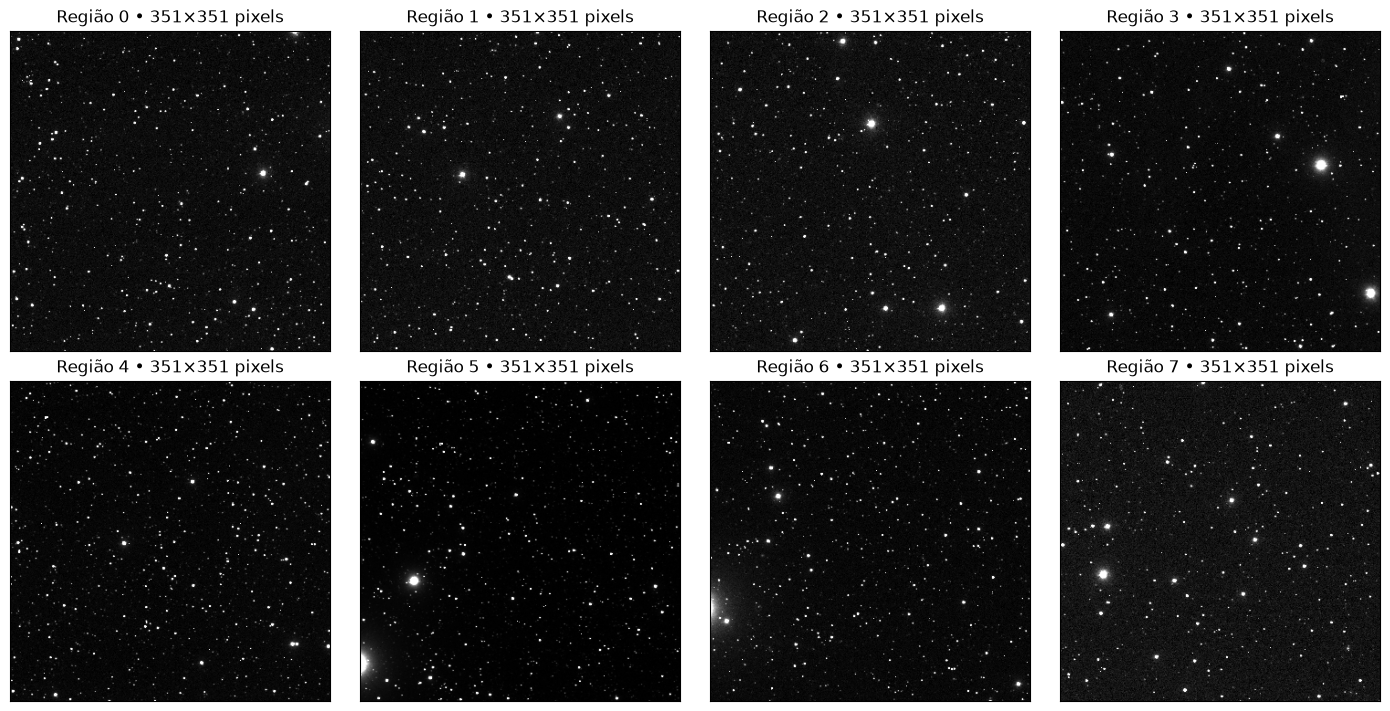

field_id,images,samples,sources,artifacts
int64,int64,int64,int64,int64
0,8,4604,1983,2621
1,8,4541,1454,3087
2,8,4147,1327,2820
3,8,3823,1754,2069
4,7,4320,2736,1584
5,8,5760,3431,2329
6,8,5445,2161,3284
7,8,3827,1253,2574


In [2]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7), layout="constrained")
for ax, field in zip(axes.flat, r["fields"]):
    rec = next(e for e in manifest["files"] if e["field_id"] == field["field_id"])
    with fits.open(ROOT / rec["path"]) as h:
        data = np.asarray(h["IMAGE"].data - h["ZODI"].data, float)
    finite = np.isfinite(data)
    lo, hi = np.percentile(data[finite], [1, 99.5])
    ax.imshow(data, origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax.set_title(f"Região {field['field_id']} • {data.shape[1]}×{data.shape[0]} pixels")
    ax.set_xticks([])
    ax.set_yticks([])
fig.savefig(OUT / "observed_fields.png", dpi=150)
plt.show()
display(Table(rows=r["fields"]))

## Avaliação em regiões separadas

Os exemplos positivos são fontes SPHEREx com contraparte Gaia isolada e núcleo
sem flags de defeito. Os negativos são picos realmente observados com flags de
contaminação instrumental. Ausência no Gaia sozinha nunca cria um negativo.

O modelo continua classificando fonte observada contra contaminação instrumental
na exposição nativa. Movimento e identificação de asteroides são etapas separadas.
As consultas Gaia assíncronas evitam o limite de 2.000 linhas das consultas
síncronas, e os catálogos completos ficam em `data/expanded/field*/gaia.ecsv`.

In [3]:
m = r["training"]
print("Estado:", m["status"])
print(f"Tempo total do treino: {m.get('wall_seconds', 0):.2f} s; limite 120 s")
print("Partições por região:", r["partitions"])
if m["status"] == "complete":
    print("Exemplos de treino / validação / teste:", m["n_train"], m["n_validation"], m["n_test"])
    matrix = np.array(m["confusion_matrix"])
    print(f"Acertos nas regiões reservadas: {np.trace(matrix)}/{matrix.sum()}")
    display(Table(rows=matrix, names=["previsto_instrumental", "previsto_fonte"]))

Estado: complete
Tempo total do treino: 1.81 s; limite 120 s
Partições por região: {'train': [0, 1, 2, 3, 4], 'validation': [5], 'test': [6, 7]}
Exemplos de treino / validação / teste: 21435 5177 8239
Acertos nas regiões reservadas: 8124/8239


previsto_instrumental,previsto_fonte
int64,int64
4747,78
37,3377


## Ranking com o modelo ampliado

O modelo ampliado fica ativo para o comando `sprints`. O ranking e as trajetórias
da sequência de demonstração original são refeitos com ele e ficam em
`outputs/expanded_demo/`. Essa sequência não representa todas as regiões de
avaliação; serve para visualizar o uso do modelo no protótipo.

ordem,id,prioridade,classe,epocas
int64,int64,float64,str15,int64
1,38,99.6,fonte_candidata,5
2,81,99.6,fonte_candidata,5
3,199,99.6,fonte_candidata,5
4,11,99.5,fonte_candidata,5
5,61,99.3,fonte_candidata,7
6,24,99.3,fonte_candidata,5
7,23,99.3,fonte_candidata,7
8,116,99.1,fonte_candidata,5
9,94,99.1,fonte_candidata,6


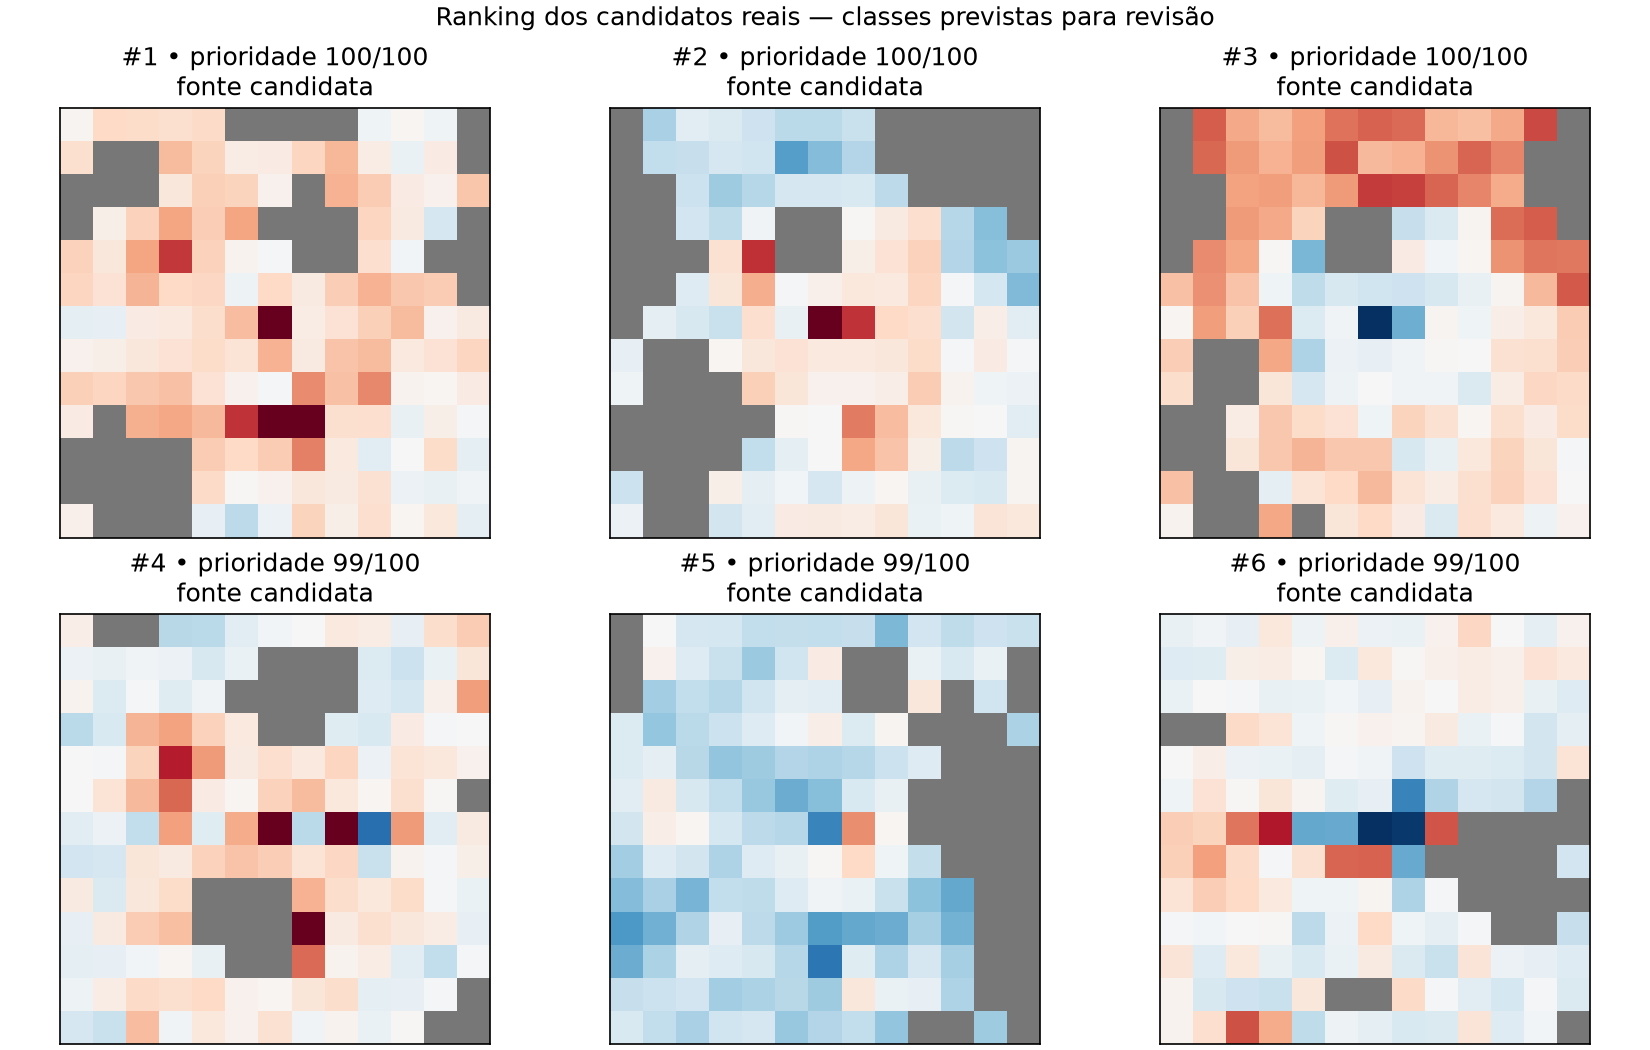

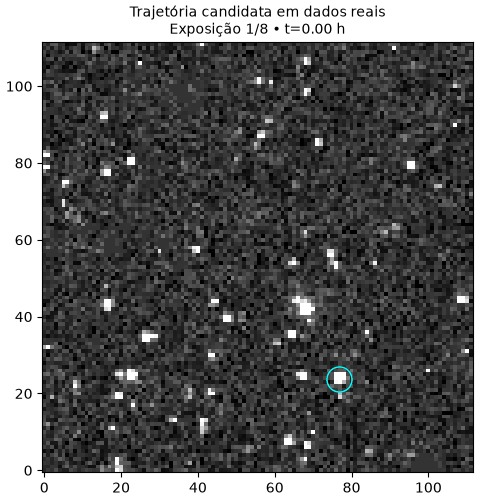

In [4]:
DEMO = ROOT / "outputs/expanded_demo"
if (DEMO / "candidate_ranking.json").exists():
    ranking = json.loads((DEMO / "candidate_ranking.json").read_text())
    display(
        Table(
            rows=[
                {
                    "ordem": c["rank"],
                    "id": c["candidate_id"],
                    "prioridade": round(c["priority_score"], 1),
                    "classe": c["predicted_class"],
                    "epocas": c["motion_support_epochs"],
                }
                for c in ranking[:10]
            ]
        )
    )
    display(Image(filename=str(DEMO / "ranking.png")))
    if (DEMO / "candidate_blink.gif").exists():
        display(Image(filename=str(DEMO / "candidate_blink.gif")))

## Repetir

```bash
uv run --extra ml spherex-tracking expand
```

O padrão busca oito exposições em cada uma das oito regiões e reutiliza arquivos
já baixados. `--per-field` muda a quantidade por região. O treino mantém o limite
de 120 segundos, com interrupção forçada se ultrapassar.

Para usar o modelo ativo no protótipo:
```bash
uv run --extra ml spherex-tracking sprints --reuse-training
```
A origem das imagens, falhas de download e contagens estão no manifesto;
`training_samples.csv` registra os exemplos e sua partição para auditoria.

In [5]:
display(JSON(r))

<IPython.core.display.JSON object>